# Abbildungen für die Projektdokumentation

Erzeugt die vier Abbildungen der Dokumentation (englisch beschriftet) und speichert sie als PNG in `figures/`.
Die Berechnungen entsprechen denjenigen in `rent_factors_analysis.ipynb` (Abschnitte 4–6); dort sind die Ergebnisse ausführlich kommentiert.

**Voraussetzung:** `data_cleaning_rentals.ipynb` wurde ausgeführt (erzeugt `flatfox_rentals_clean.csv`).

| Datei | Abbildung in der Dokumentation |
|---|---|
| `figure1_sample_coverage.png` | Figure 1 – Wohnungen und Gemeindeabdeckung pro Kanton |
| `figure2_rq1_correlations.png` | Figure 2 – Korrelationen (RQ1) |
| `figure3_rq2_coefficients.png` | Figure 3 – Regressionseffekte (RQ2) |
| `figure4_rq3_urban_rural.png` | Figure 4 – Stadt vs. intermediär/ländlich (RQ3) |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"
FIG_DIR = PROJECT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,
                     "axes.spines.top": False, "axes.spines.right": False})
DPI = 300
CANTONS = ["LU", "UR", "SZ", "OW", "NW", "ZG"]

df = pd.read_csv(DATA_DIR / "flatfox_rentals_clean.csv")
gemeinden = pd.read_csv(DATA_DIR / "gemeinde_indikatoren_zentralschweiz.csv")
gemeinden["population_density_log"] = np.log(gemeinden["population_density_productive"])

typology = pd.read_excel(PROJECT_DIR / "data" / "demographic_data" / "raumgliederungen_bfs.xlsx",
                         sheet_name="Daten", header=1, skiprows=[2])
typology = typology.rename(columns={"BFS Gde-nummer": "gemeinde_bfs", "Stadt/Land-Typologie": "stadt_land_code"})

# Englische Beschriftungen der Indikatoren
LABELS = {
    "income_median_chf": "Median taxable income",
    "population_density_log": "Population density (log)",
    "employment_per_100_residents": "Employment per 100 residents",
    "population_growth_pct": "Population growth 2024–25",
    "net_migration_per_1000_residents": "Net migration per 1,000",
    "foreign_population_pct": "Foreign residents (%)",
    "vacancy_rate_pct": "Vacancy rate (%)",
    "social_assistance_rate_pct": "Social assistance rate (%)",
    "population_age65plus_pct": "Residents aged 65+ (%)",
    "household_size_mean": "Mean household size",
    "single_family_buildings_pct": "Single-family buildings (%)",
    "new_dwellings_per_1000_residents": "New dwellings per 1,000",
}

# Variablen für die Regressionen
df["log_rent_per_m2"] = np.log(df["rent_net_per_m2"])
df["log_surface"] = np.log(df["surface_living"])
df["has_balcony"] = df["attribute_reported_balconygarden"].astype(int)
df["has_lift"] = df["attribute_reported_lift"].astype(int)
df = df.merge(typology[["gemeinde_bfs", "stadt_land_code"]], on="gemeinde_bfs", how="left", validate="many_to_one")
df["group"] = np.where(df["stadt_land_code"] == 1, "urban", "intermediate/rural")
CONTROLS = "log_surface + number_of_rooms + has_balcony + has_lift"


def spearman_ci(x, y):
    rho, p = stats.spearmanr(x, y)
    n = len(x)
    se = 1.06 / np.sqrt(n - 3)
    z = np.arctanh(rho)
    return rho, p, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se), n


def indicator_effects(data):
    # Ein Modell pro Indikator: Effekt in % pro SD, cluster-robust nach Gemeinde
    rows = []
    data = data.copy()
    for col, label in LABELS.items():
        data["z"] = (data[col] - data[col].mean()) / data[col].std()
        sub = data.dropna(subset=["z"])
        model = smf.ols(f"log_rent_per_m2 ~ {CONTROLS} + z", data=sub).fit(
            cov_type="cluster", cov_kwds={"groups": sub["gemeinde_bfs"]})
        lo, hi = model.conf_int().loc["z"]
        rows.append({"label": label, "effect": 100 * (np.exp(model.params["z"]) - 1),
                     "lo": 100 * (np.exp(lo) - 1), "hi": 100 * (np.exp(hi) - 1), "p": model.pvalues["z"]})
    return pd.DataFrame(rows)


print(f"{len(df)} Wohnungen, {df['gemeinde_bfs'].nunique()} Gemeinden")

332 Wohnungen, 82 Gemeinden


## Figure 1 – Stichprobe und Gemeindeabdeckung

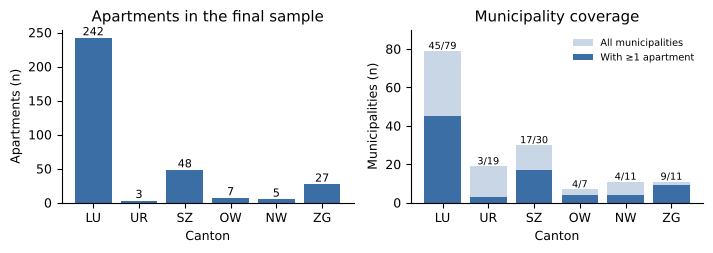

In [2]:
n_apartments = df["kanton_geo"].value_counts().reindex(CANTONS, fill_value=0)
n_covered = df.groupby("kanton_geo")["gemeinde_bfs"].nunique().reindex(CANTONS, fill_value=0)
n_total = gemeinden.groupby("kanton_geo").size().reindex(CANTONS)

plt.rcParams["font.size"] = 9  # Figure 1 mit etwas grösserer Schrift (breiteres Format)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
ax[0].bar(CANTONS, n_apartments, color="#3a6ea5")
for i, v in enumerate(n_apartments):
    ax[0].text(i, v + 4, str(v), ha="center", fontsize=8)
ax[0].set(title="Apartments in the final sample", ylabel="Apartments (n)", xlabel="Canton")

ax[1].bar(CANTONS, n_total, color="#c9d6e6", label="All municipalities")
ax[1].bar(CANTONS, n_covered, color="#3a6ea5", label="With ≥1 apartment")
for i, (a, b) in enumerate(zip(n_covered, n_total)):
    ax[1].text(i, b + 1, f"{a}/{b}", ha="center", fontsize=7)
ax[1].set(title="Municipality coverage", ylabel="Municipalities (n)", xlabel="Canton", ylim=(0, 90))
ax[1].legend(frameon=False, fontsize=7)

plt.tight_layout()
fig.savefig(FIG_DIR / "figure1_sample_coverage.png", dpi=DPI)
plt.show()
plt.rcParams["font.size"] = 8.5

## Figure 2 – Korrelationen auf Gemeindeebene (RQ1)

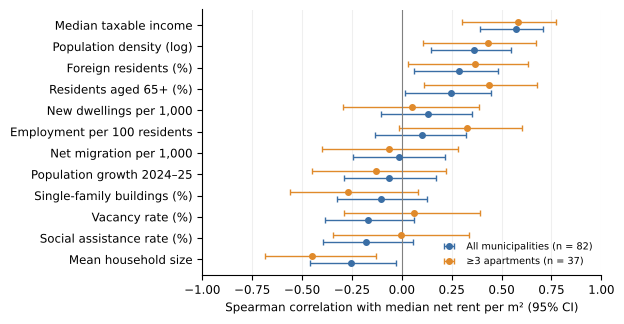

In [3]:
muni = (df.groupby("gemeinde_bfs")
        .agg(median_rent=("rent_net_per_m2", "median"), n=("pk", "size"))
        .reset_index()
        .merge(gemeinden, on="gemeinde_bfs", validate="one_to_one"))

rows = []
for col, label in LABELS.items():
    for name, data in [("All municipalities", muni), ("≥3 apartments", muni[muni["n"] >= 3])]:
        sub = data[[col, "median_rent"]].dropna()
        rho, p, lo, hi, n = spearman_ci(sub[col], sub["median_rent"])
        rows.append({"label": label, "sample": name, "rho": rho, "lo": lo, "hi": hi, "n": n})
corr = pd.DataFrame(rows)
order = corr[corr["sample"] == "All municipalities"].sort_values("rho")["label"].tolist()

fig, ax = plt.subplots(figsize=(6.3, 3.3))
for name, offset, color in [("All municipalities", -0.17, "#3a6ea5"), ("≥3 apartments", 0.17, "#e08a2b")]:
    g = corr[corr["sample"] == name].set_index("label").loc[order]
    y = np.arange(len(order)) + offset
    ax.errorbar(g["rho"], y, xerr=[g["rho"] - g["lo"], g["hi"] - g["rho"]], fmt="o", ms=4, color=color,
                capsize=2, lw=1, label=f"{name} (n = {int(g['n'].max())})")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman correlation with median net rent per m² (95% CI)")
ax.legend(fontsize=7, loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
fig.savefig(FIG_DIR / "figure2_rq1_correlations.png", dpi=DPI)
plt.show()

## Figure 3 – Regressionseffekte mit Wohnungs-Kontrollen (RQ2)

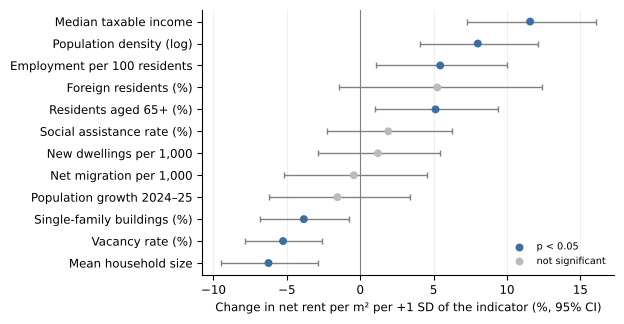

,label,effect,lo,hi,p
9,Mean household size,-6.25,-9.48,-2.90,0.00
6,Vacancy rate (%),-5.26,-7.84,-2.61,0.00
10,Single-family buildings (%),-3.84,-6.80,-0.79,0.01
3,Population growth 2024–25,-1.55,-6.24,3.38,0.53
4,"Net migration per 1,000",-0.44,-5.20,4.56,0.86
11,"New dwellings per 1,000",1.20,-2.88,5.46,0.57
7,Social assistance rate (%),1.91,-2.27,6.26,0.38
8,Residents aged 65+ (%),5.13,1.03,9.40,0.01
5,Foreign residents (%),5.25,-1.42,12.37,0.13
2,Employment per 100 residents,5.45,1.10,9.98,0.01


In [4]:
effects = indicator_effects(df).sort_values("effect")
significant = effects["p"] < 0.05

fig, ax = plt.subplots(figsize=(6.3, 3.3))
ax.errorbar(effects["effect"], effects["label"],
            xerr=[effects["effect"] - effects["lo"], effects["hi"] - effects["effect"]],
            fmt="none", ecolor="grey", capsize=2, lw=1)
ax.scatter(effects["effect"], effects["label"], c=np.where(significant, "#3a6ea5", "#bbbbbb"), s=22, zorder=3)
ax.scatter([], [], c="#3a6ea5", s=22, label="p < 0.05")
ax.scatter([], [], c="#bbbbbb", s=22, label="not significant")
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Change in net rent per m² per +1 SD of the indicator (%, 95% CI)")
ax.legend(fontsize=7, loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
fig.savefig(FIG_DIR / "figure3_rq2_coefficients.png", dpi=DPI)
plt.show()
effects.round(2)

## Figure 4 – Städtisch vs. intermediär/ländlich (RQ3)

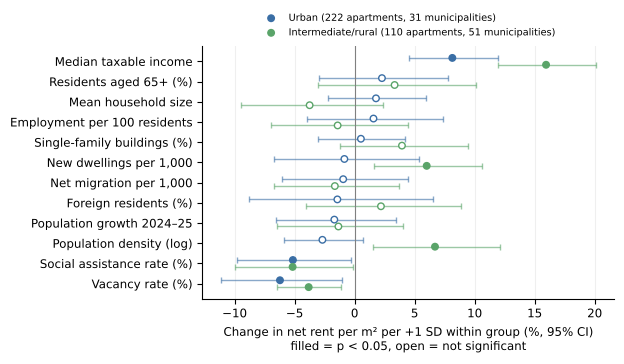

In [5]:
groups = {
    "urban": ("#3a6ea5", 0.17),
    "intermediate/rural": ("#5aa469", -0.17),
}
by_group = {g: indicator_effects(df[df["group"] == g]).set_index("label") for g in groups}
order = by_group["urban"].sort_values("effect").index.tolist()

fig, ax = plt.subplots(figsize=(6.3, 3.7))
for g, (color, offset) in groups.items():
    e = by_group[g].loc[order]
    sub = df[df["group"] == g]
    y = np.arange(len(order)) + offset
    ax.errorbar(e["effect"], y, xerr=[e["effect"] - e["lo"], e["hi"] - e["effect"]],
                fmt="none", ecolor=color, alpha=0.6, capsize=2, lw=1)
    ax.scatter(e["effect"], y, s=22, facecolors=np.where(e["p"] < 0.05, color, "white"), edgecolors=color, zorder=3,
               label=f"{g.capitalize()} ({len(sub)} apartments, {sub['gemeinde_bfs'].nunique()} municipalities)")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Change in net rent per m² per +1 SD within group (%, 95% CI)\nfilled = p < 0.05, open = not significant")
ax.legend(fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
fig.savefig(FIG_DIR / "figure4_rq3_urban_rural.png", dpi=DPI)
plt.show()

In [6]:
print("Gespeichert in", FIG_DIR.relative_to(PROJECT_DIR))
for f in sorted(FIG_DIR.glob("*.png")):
    print(" ", f.name)

Gespeichert in figures
  figure1_sample_coverage.png
  figure2_rq1_correlations.png
  figure3_rq2_coefficients.png
  figure4_rq3_urban_rural.png
